# Credit Score Model 2.1

Cambios respecto a la 2.0:

1. Imports que faltaban (`precision_score`, `recall_score`, `clone`, `ks_2samp`), para que el cuaderno corra de principio a fin.
2. `loan_percent_income` se recalcula como `loan_amnt / person_income`, igual que la API (en 338 filas el CSV no cuadra).
3. Se define `modelo_final` (celda 6.1). Se probó la calibración isotónica: el Brier apenas mejora (0.0921 a 0.0917), el Gini baja un poco y cada predicción cuesta 3 veces más, así que el modelo final es el XGBoost sin calibrar.
4. Fuga de datos: la versión C calcula sus propias métricas en vez de reutilizar variables de otra celda.
5. Monitorización: la PD de referencia del PSI sale del mismo modelo que se monitoriza; la deriva cambia las variables crudas y se recalculan las derivadas; se simula una deriva de concepto (más impagos en el segmento afectado); se añade la gráfica del NPL.
6. `prestamos_scored.csv` incluye la columna `conjunto` (entrenamiento, prueba o producción).

In [1]:
#Librerias

import pandas as pd
import shap
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import brier_score_loss, precision_score, recall_score, roc_auc_score
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from scipy.stats import ks_2samp
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier



/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Data import

# En Colab el CSV está en /content; en el repo, en data/; si no, junto al cuaderno
rutas = ["/content/credit_risk_dataset.csv", "../data/credit_risk_dataset.csv", "credit_risk_dataset.csv"]
ruta = next(r for r in rutas if os.path.exists(r))
data = pd.read_csv(ruta)
data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [4]:
#Simple Exploration

size = data.shape
print("Data Size:", size, "\n")
print(data.dtypes, "\n")
print(data.isna().sum(), "\n")
print(data.duplicated().sum(), "\n")

Data Size: (32581, 12) 

person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object 

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64 

165 



In [5]:
# 1. Calidad de Datos

# Eliminar edades o antigüedades laborales irreales (+100 años de vida y +60 años trabajando)
df = data.copy()
df = df.drop_duplicates()
df = df[(df["person_age"] <= 100) & ((df["person_emp_length"] <= 60) | (df["person_emp_length"].isna()))].copy() #Se dejan de ignorar los empleos null,

# loan_percent_income se recalcula como loan_amnt / person_income: en 338 filas el CSV no cuadra,
# y la API lo calcula así, de modo que el modelo entrena con el mismo valor que recibirá en producción
df["loan_percent_income"] = (df["loan_amnt"] / df["person_income"]).round(2)

print(df.shape)
df.describe()

(32409, 12)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32409.000000,3.240900e+04,31522.000000,32409.000000,29315.000000,32409.000000,32409.000000,32409.000000
mean,27.730754,6.589428e+04,4.782850,9592.486655,11.017099,0.218705,0.170585,5.811194
std,6.210445,5.251787e+04,4.037343,6320.885127,3.241718,0.413374,0.107089,4.057899
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12250.000000,13.470000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [6]:
# 2. Regulaciónes EBA/BCE (EBA/GL/2020/06)

#La EBA exige evaluar capacidad de pago futura (DSTI: Debt Service-to-Income)

# 2.1 Se simula una cuota mensual asumiendo un plazo estándar de 36 meses para calcular el DSTI y una tasa fija al 10%
tasa_mensual = 0.10 / 12
plazo_meses = 36
cuota_mensual = (df["loan_amnt"] * tasa_mensual) / ( 1 - (1 + tasa_mensual) ** (-plazo_meses)) #Formula Amortizacion francesa a cuota fija
ingreso_mensual = df["person_income"] / 12

#DSTI (Cuota mensual / Ingreso mensual) (Capacidad real de pago por historial pasado y capacidad futura de rembolso)
df["dsti_ratio"] = cuota_mensual / ingreso_mensual

#-------------------------------
tasa_real = (df["loan_int_rate"].fillna(df["loan_int_rate"].median()) / 100) / 12
df["dsti_ratio_real"] = (
    (df["loan_amnt"] * tasa_real) / (1 - (1 + tasa_real) ** (-plazo_meses))
) / ingreso_mensual


In [7]:
# 3. Datos de entrenamiento, validación y produccion

#Variable target: loan_status (Si el prestamo ya fue pagado = 0 o aun no ha sido pagado = 1) 1.Default, 0. non-default
# Se excluyen "loan_grade" y "loan_int_rate" por fuga de datos
target = "loan_status"
features = ["person_age", "person_income", "person_home_ownership", "person_emp_length", "loan_intent",
            "loan_amnt", "loan_percent_income", "cb_person_default_on_file", "cb_person_cred_hist_length",
            "dsti_ratio"]

X = df[features]
y = df[target]

#Split de datos Entrenamiento-Validación / Produccion 80:20 (Para el drift-data) (Dataset 100%)
X_hist, X_prod_raw, y_hist, y_prod_raw = train_test_split(X, y, test_size=0.2, random_state=2, stratify=y)

#Split de datos Entrenamiento / Validación 80:20 (Dataset 80%)
X_train, X_test, y_train, y_test = train_test_split(X_hist, y_hist, test_size=0.2, random_state=2, stratify=y_hist)

#Preprocesamiento de datos
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist() #Se agrega el "string" para evitar el error de pandas

preprocessor = ColumnTransformer(
  transformers=[("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
                ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
                  ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])


In [8]:
# 4. Definición de los modelos (LogReg y XGBoost)
# La normativa BCE exigue demostrar que el uso de un modelo más complejo esta justificado por su rendimiento superior

modelo_base = Pipeline([("prep", preprocessor),
                        ("clf", LogisticRegression(max_iter=1000))])

modelo_ml = Pipeline([("prep", preprocessor),
                      ("clf", XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=2, eval_metric="logloss"))])


In [9]:
# 5. Entrenamiento de los modelos

modelo_base.fit(X_train, y_train)
modelo_ml.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_age','person_income','person_home_ownership',..., 'cb_person_default_on_file','cb_person_cred_hist_length','dsti_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [10]:
# 6. Métricas de justificación del modelo de entrenamiento utilizado
for nombre, mod in [
    ("Regresión Logística (Base)", modelo_base),
    ("XGBoost (Mejora)", modelo_ml),
]:
    prob = mod.predict_proba(X_test)[:, 1]
    preds = (prob >= 0.25).astype(int)
    auc = roc_auc_score(y_test, prob)
    gini = 2 * auc - 1
    ks = ks_2samp(prob[y_test == 0], prob[y_test == 1]).statistic
    brier = brier_score_loss(y_test, prob)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    print(f"{nombre}: ")
    print(f"AUC-ROC: {auc:.4f} | Índicex Gini: {gini:.4f} | KS: {ks:.4f} | Brier Score: {brier:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} \n")

probs_final = modelo_ml.predict_proba(X_test)[:, 1]
bandas = pd.cut(probs_final, bins=[0, 0.1, 0.2, 0.3, 0.5, 1.0])
print("=== BANDAS DE PD (PREDICHA VS MORA REAL) ===")
print(
    pd.DataFrame({"pd": probs_final, "real": y_test})
    .groupby(bandas, observed=False)
    .agg(
        total=("real", "count"),
        pd_media=("pd", "mean"),
        mora_real=("real", "mean"),
    ),
    "\n",
)

Regresión Logística (Base): 
AUC-ROC: 0.7899 | Índicex Gini: 0.5797 | KS: 0.4283 | Brier Score: 0.1284 | Precision: 0.4644 | Recall: 0.6279 

XGBoost (Mejora): 
AUC-ROC: 0.8686 | Índicex Gini: 0.7371 | KS: 0.5718 | Brier Score: 0.0921 | Precision: 0.6562 | Recall: 0.6667 

=== BANDAS DE PD (PREDICHA VS MORA REAL) ===
            total  pd_media  mora_real
(0.0, 0.1]   2173  0.053304   0.048780
(0.1, 0.2]   1622  0.140861   0.136868
(0.2, 0.3]    386  0.242122   0.227979
(0.3, 0.5]    409  0.382904   0.386308
(0.5, 1.0]    596  0.895419   0.939597 



In [11]:
# 6.1 Modelo final: XGBoost sin calibrar frente a una versión calibrada (isotónica)
modelo_calibrado = CalibratedClassifierCV(modelo_ml, method="isotonic", cv=3).fit(X_train, y_train)
prob_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

for nombre, p in [("XGBoost sin calibrar", probs_final), ("XGBoost calibrado", prob_cal)]:
    print(f"{nombre}: Gini {2 * roc_auc_score(y_test, p) - 1:.4f} | Brier {brier_score_loss(y_test, p):.4f}")

# La calibración apenas mejora el Brier (0.0921 -> 0.0917), baja un poco el Gini y cada predicción
# cuesta 3 veces más (son 3 modelos promediados), así que el modelo final es el XGBoost sin calibrar
modelo_final = modelo_ml

XGBoost sin calibrar: Gini 0.7371 | Brier 0.0921
XGBoost calibrado: Gini 0.7356 | Brier 0.0917


In [12]:
# 7. Evaluación de Solicitud de crédito (Asumiendo un Margen DSTI máximo de 35%, un PD del 25% y un Margen de Conservación (MoC))
def evaluar_solicitud_credito(modelo, datos_cliente, umbral_pd=0.25, max_dsti=0.35):

    pd_estimada = modelo.predict_proba(datos_cliente)[:, 1]
    # Se aplica el Margen de Conservadurismo (MoC) de un +10% sobre la PD estimada
    pd_prudencial = np.clip(pd_estimada * 1.10, 0, 1)

    decisiones = []
    umbral = []
    for i in range(len(datos_cliente)):
        dsti = datos_cliente.iloc[i]["dsti_ratio"]
        pd_val = pd_prudencial[i]
        if dsti > max_dsti:
            decisiones.append("RECHAZADO (Incumple límite DSTI EBA > 35%)")
            umbral.append(f"DSTI: {dsti:.2%}")
        elif pd_val > umbral_pd:
            decisiones.append(f"RECHAZADO")
            umbral.append(f"PD: {pd_val:.2%}")
        else:
            decisiones.append(f"APROBADO")
            umbral.append(f"PD: {pd_val:.2%}")
    return decisiones, umbral

decisiones, umbral = evaluar_solicitud_credito(modelo_ml, X_test.iloc[:100], umbral_pd=0.25, max_dsti=0.35)
print(decisiones)
print(umbral)


['APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'RECHAZADO', 'RECHAZADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'RECHAZADO', 'RECHAZADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'RECHAZADO', 'RECHAZADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'RECHAZADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 'RECHAZADO', 'APROBADO', 'APROBADO', 'APROBADO', 

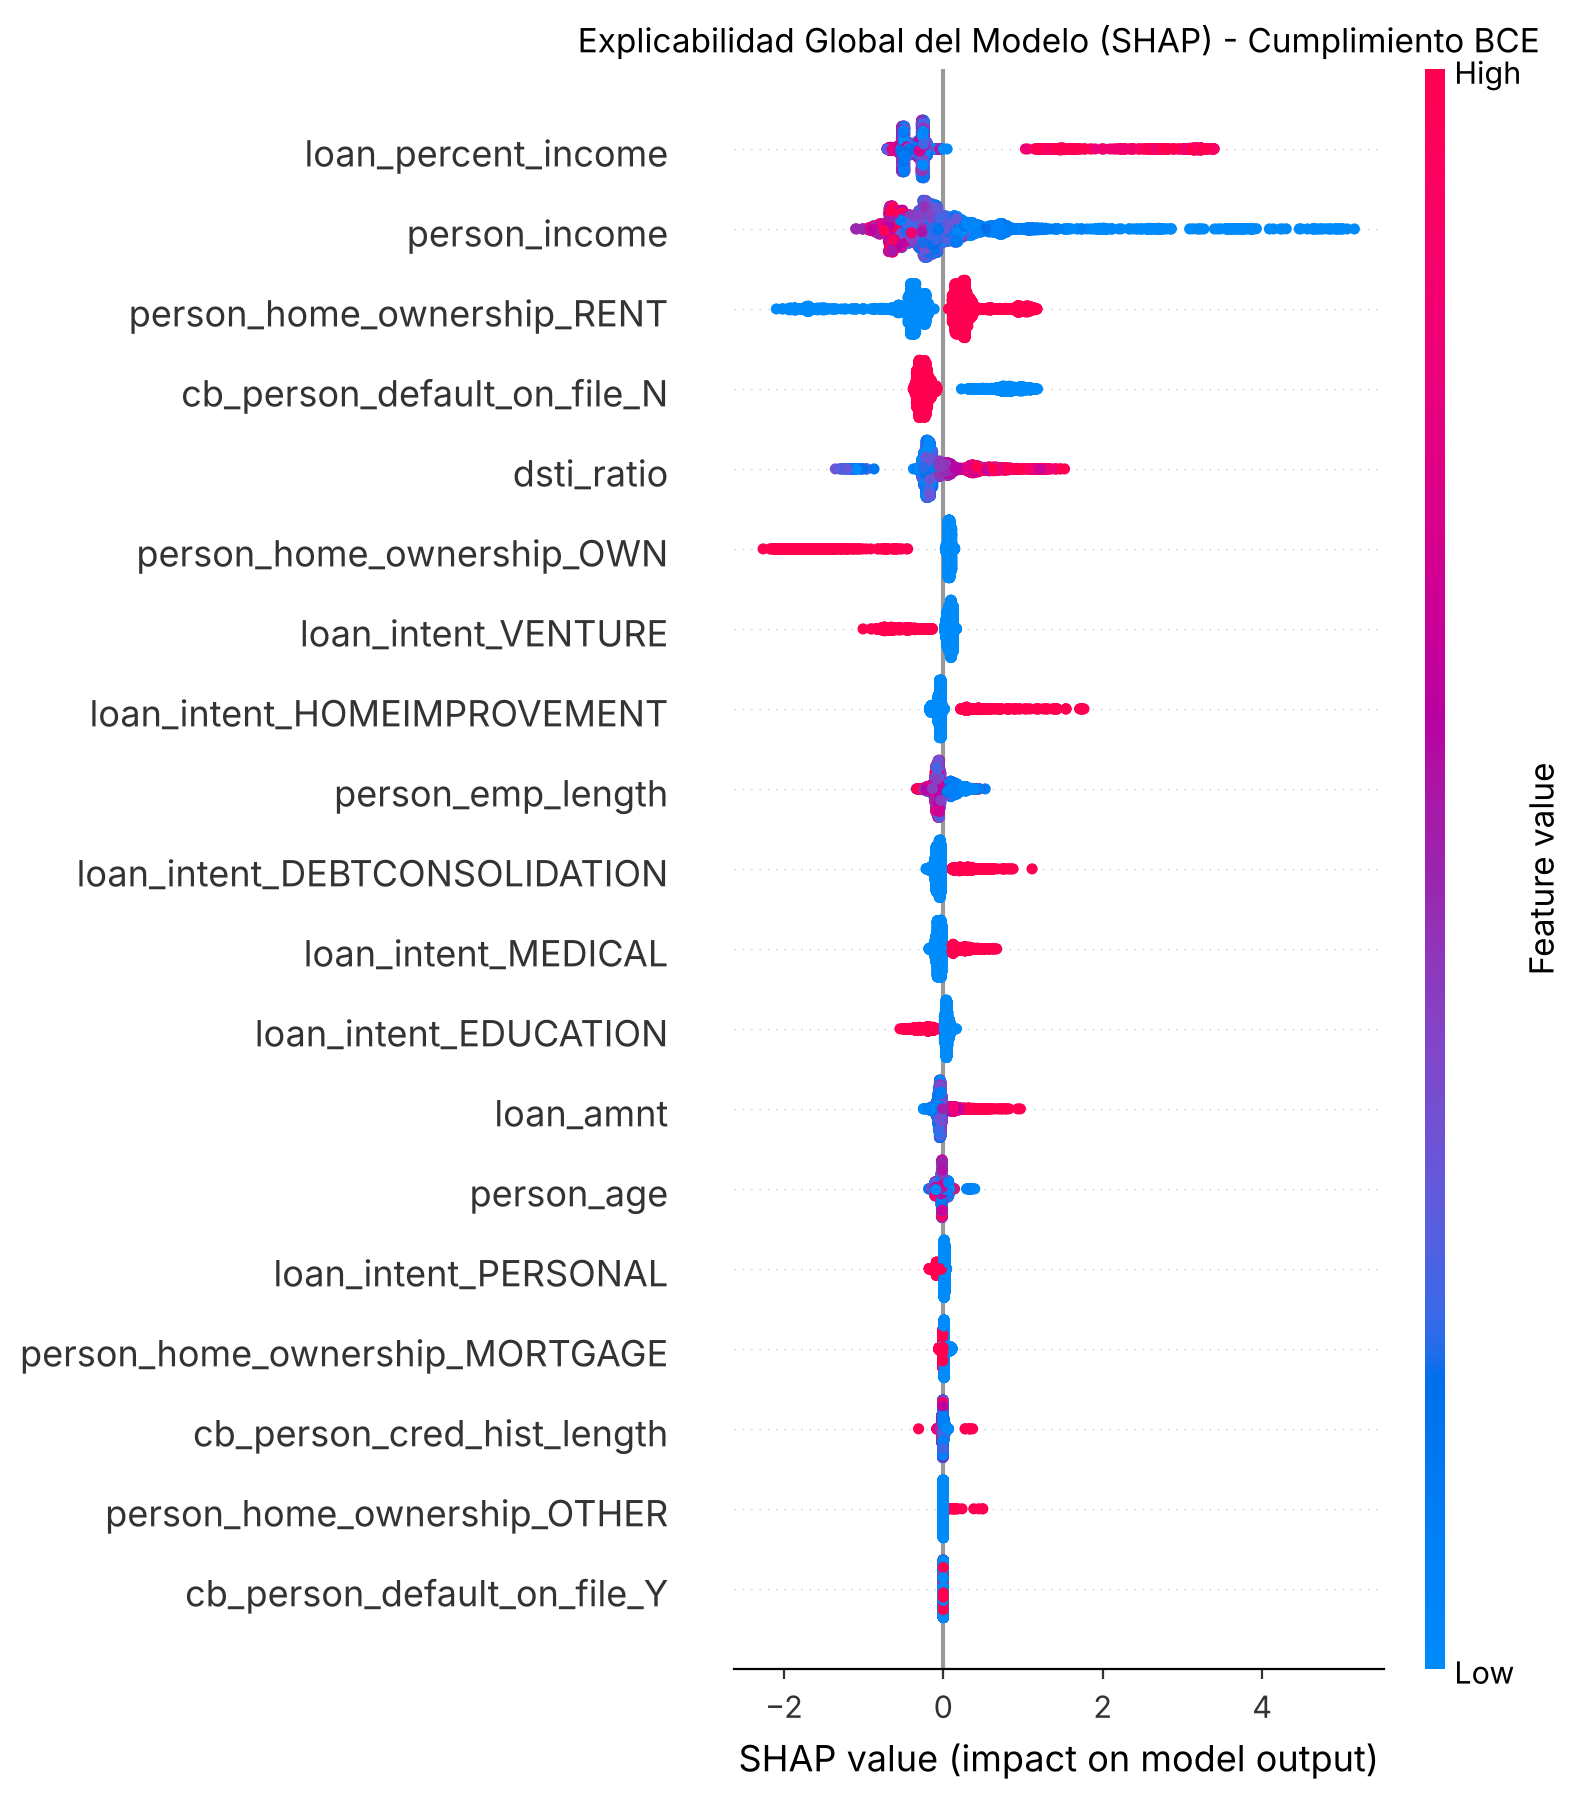

In [13]:
# 8. Justificación de Atributos (Razones) al otorgar o rechazar un prestamo. (Evaluación SHAP)
# Se extraen el modelo de entrenamiento y los nombres de las variables para la evaluación SHAP
X_test_processed = modelo_ml.named_steps["prep"].transform(X_test)
feature_names = num_cols + list(modelo_ml.named_steps["prep"].named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat_cols))

explainer = shap.TreeExplainer(modelo_ml.named_steps["clf"])
shap_values = explainer.shap_values(X_test_processed)

# Gráfico de explicabilidad SHAP
plt.figure()
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names, show=False)
plt.title("Explicabilidad Global del Modelo (SHAP) - Cumplimiento BCE")
plt.tight_layout()
plt.savefig("shap_explicabilidad_bce.png", dpi=300)


In [14]:
# 9. Comparativa de Fuga de Datos (Data Leakage)

features_A = [f if f != "dsti_ratio" else "dsti_ratio_real" for f in features] + ["loan_grade", "loan_int_rate"]
features_B = [f if f != "dsti_ratio" else "dsti_ratio_real" for f in features]

def medir_fuga(cols):
    mod = clone(modelo_ml)
    num_c = df[cols].select_dtypes(include=["int64", "float64"]).columns.tolist()
    cat_c = df[cols].select_dtypes(include=["object", "string"]).columns.tolist()
    mod.named_steps["prep"].transformers = [
      (t[0], t[1], num_c if t[0] == "num" else cat_c)
      for t in mod.named_steps["prep"].transformers
  ]
    mod.fit(df.loc[X_train.index, cols], y_train)
    p = mod.predict_proba(df.loc[X_test.index, cols])[:, 1]
    auc = roc_auc_score(y_test, p)
    ks = ks_2samp(p[y_test == 0], p[y_test == 1]).statistic
    preds = (p >= 0.25).astype(int)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    return {
        "AUC": round(float(auc), 4),
        "Gini": round(float(2 * auc - 1), 4),
        "Brier": round(float(brier_score_loss(y_test, p)), 4),
        "KS": round(float(ks), 4),
        "Precision": round(float(prec), 4),
        "Recall": round(float(rec), 4)
    }

def metricas_LogReg(cols):
    mod = clone(modelo_base)
    mod.fit(X_train, y_train)
    p = mod.predict_proba(df.loc[X_test.index, cols])[:, 1]
    auc = roc_auc_score(y_test, p)
    ks = ks_2samp(p[y_test == 0], p[y_test == 1]).statistic
    preds = (p >= 0.25).astype(int)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    return {
        "AUC": round(float(auc), 4),
        "Gini": round(float(2 * auc - 1), 4),
        "Brier": round(float(brier_score_loss(y_test, p)), 4),
        "KS": round(float(ks), 4),
        "Precision": round(float(prec), 4),
        "Recall": round(float(rec), 4)
    }


print("=== TABLA COMPARATIVA DE FUGA ===")
print("Version LogReg (Sin Fuga):                     ", metricas_LogReg(features))
print("Versión A (Con grade/int_rate):                ", medir_fuga(features_A))
print("Versión B (Sin grade/int_rate):                ", medir_fuga(features_B))
preds_c = (probs_final >= 0.25).astype(int)
print("Versión C (Sin fuga (Sin grade/sin int_rate)): ",
{
  "AUC": round(float(roc_auc_score(y_test, probs_final)), 4),
  "Gini": round(float(2 * roc_auc_score(y_test, probs_final) - 1), 4),
  "Brier": round(float(brier_score_loss(y_test, probs_final)), 4),
  "KS": round(float(ks_2samp(probs_final[y_test == 0], probs_final[y_test == 1]).statistic), 4),
  "Precision": round(float(precision_score(y_test, preds_c)), 4),
  "Recall": round(float(recall_score(y_test, preds_c)), 4)
})

=== TABLA COMPARATIVA DE FUGA ===
Version LogReg (Sin Fuga):                      {'AUC': 0.7899, 'Gini': 0.5797, 'Brier': 0.1284, 'KS': 0.4283, 'Precision': 0.4644, 'Recall': 0.6279}


Versión A (Con grade/int_rate):                 {'AUC': 0.9215, 'Gini': 0.843, 'Brier': 0.064, 'KS': 0.7081, 'Precision': 0.769, 'Recall': 0.769}


Versión B (Sin grade/int_rate):                 {'AUC': 0.8757, 'Gini': 0.7515, 'Brier': 0.0895, 'KS': 0.5953, 'Precision': 0.6673, 'Recall': 0.6702}
Versión C (Sin fuga (Sin grade/sin int_rate)):  {'AUC': 0.8686, 'Gini': 0.7371, 'Brier': 0.0921, 'KS': 0.5718, 'Precision': 0.6562, 'Recall': 0.6667}


=== MONITORIZACIÓN POR LOTES ===
  lote  psi_score  ks_drift  gini_lote  npl_predicho  npl_real  tasa_aprobacion
 Mes_1     0.0093    0.0280     0.8181        0.0915    0.0628           0.7357
 Mes_2     0.0104    0.0277     0.7199        0.0930    0.0978           0.7560
 Mes_3     0.0146    0.0326     0.8025        0.0946    0.0761           0.7296
 Mes_4     0.0180    0.0608     0.7796        0.0893    0.0664           0.7815
 Mes_5     0.0328    0.0716     0.8082        0.0979    0.0897           0.7019
 Mes_6     0.0110    0.0249     0.7416        0.0949    0.0973           0.7611
 Mes_7     0.2546    0.2086     0.5818        0.1071    0.1143           0.5833
 Mes_8     0.2375    0.1981     0.5553        0.1028    0.1318           0.5759
 Mes_9     0.2775    0.2216     0.5483        0.1074    0.1579           0.5630
Mes_10     0.3672    0.2435     0.4498        0.1072    0.1449           0.5241
Mes_11     0.3481    0.2448     0.3652        0.1083    0.2281           0.5278
Mes_12 

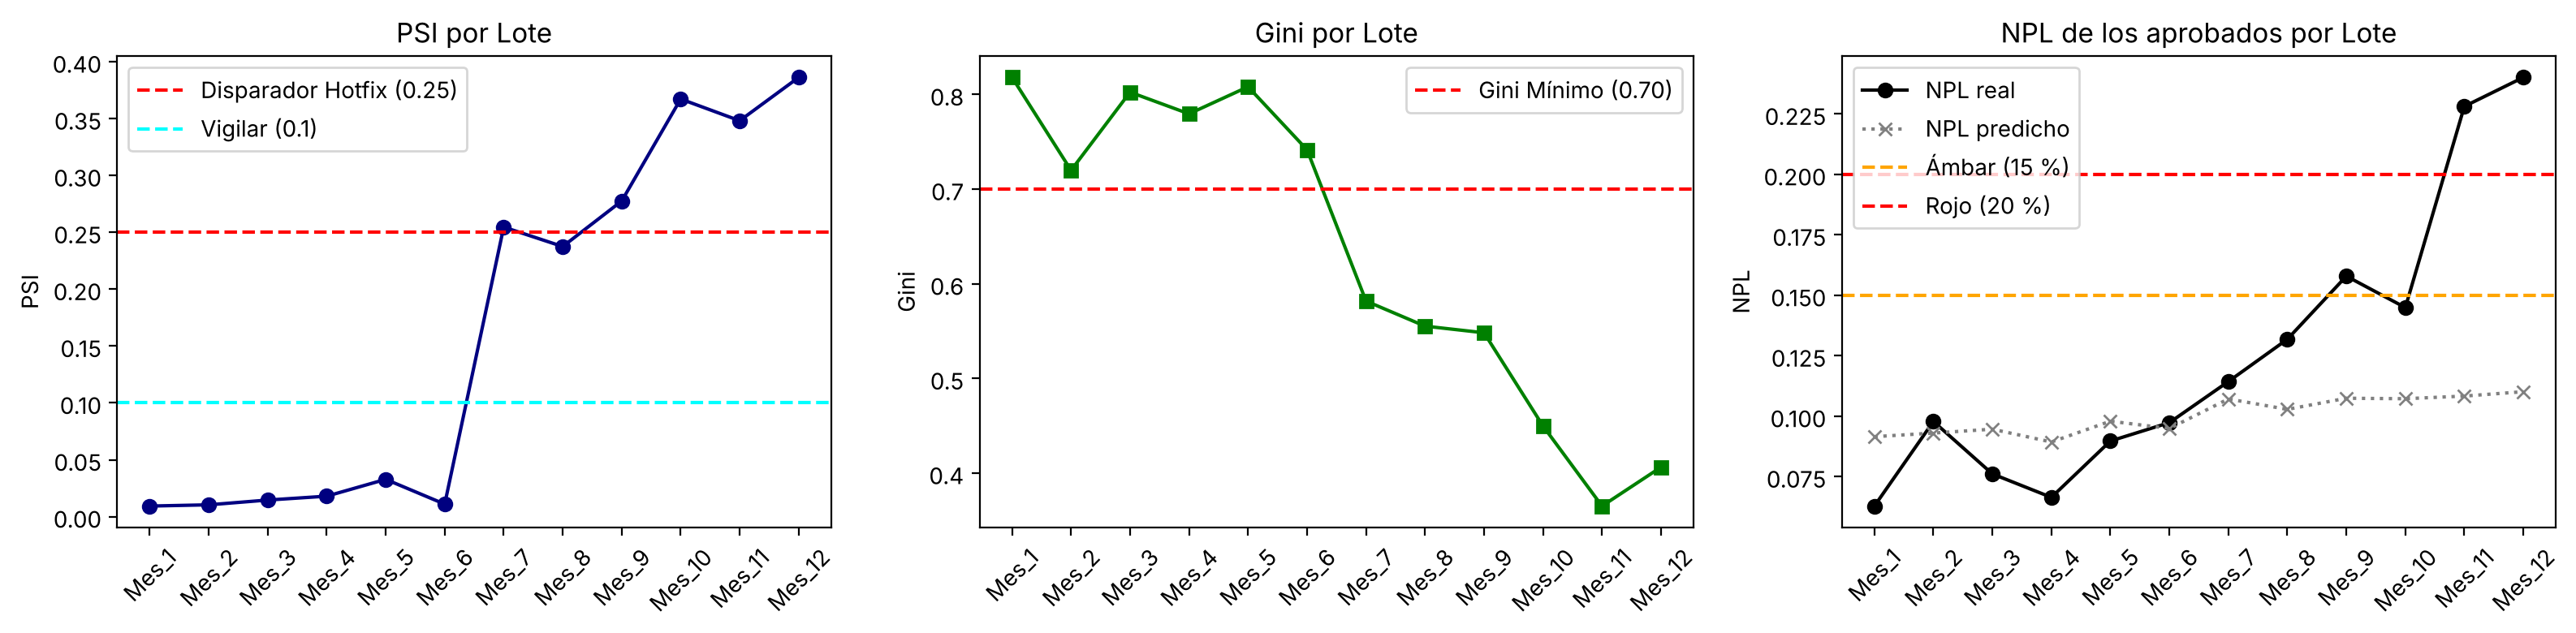

In [15]:
# 10. Simulación de Monitorización Mensual (PSI/Gini/NPL) por un año

def calcular_psi(esperado, actual, bins=10):
  puntos = np.percentile(esperado, np.linspace(0, 100, bins + 1))
  puntos[0] = -np.inf
  puntos[-1] = np.inf

  hist_esp = np.histogram(esperado, bins=puntos)[0] / len(esperado)
  hist_act = np.histogram(actual, bins=puntos)[0] / len(actual)

  esp = np.where(hist_esp == 0, 1e-4, hist_esp)
  act = np.where(hist_act == 0, 1e-4, hist_act)
  return float(np.sum((act - esp) * np.log(act / esp)))

def recalcular_variables(X_l):
  # Las variables derivadas se recalculan con la misma fórmula que el entrenamiento y la API
  X_l["loan_percent_income"] = (X_l["loan_amnt"] / X_l["person_income"]).round(2)
  cuota = (X_l["loan_amnt"] * tasa_mensual) / (1 - (1 + tasa_mensual) ** (-plazo_meses))
  X_l["dsti_ratio"] = cuota / (X_l["person_income"] / 12)
  return X_l

# PD de referencia del PSI: la del mismo modelo que se monitoriza, sobre el conjunto de prueba
pd_referencia = modelo_final.predict_proba(X_test)[:, 1]

# Supuestos de la crisis (se declaran en la diapositiva 9)
MES_INICIO_CRISIS = 7
CAIDA_INGRESO_JOVENES = 0.25   # los clientes de 28 años o menos pierden el 25 % de su ingreso
SUBIDA_MONTO_MENSUAL = 0.08    # el monto solicitado sube un 28 % el mes 7 y 8 puntos más cada mes
NUEVOS_IMPAGOS_MENSUAL = 0.05  # cada mes, un 5 % más de los jóvenes que pagaban pasa a impago

# Dividimos producción (20%) en 12 lotes mensuales con semillas fijas
rng = np.random.default_rng(1)
np.random.seed(1)
lotes = np.array_split(np.random.permutation(X_prod_raw.index), 12)
filas_lotes = []

for i, idx_l in enumerate(lotes, 1):
    X_l = X_prod_raw.loc[idx_l].copy().astype({"person_income": float, "loan_amnt": float})
    y_l = y_prod_raw.loc[idx_l].copy()

    if i >= MES_INICIO_CRISIS:
      meses_crisis = i - MES_INICIO_CRISIS + 1  # 1 el mes 7, 2 el mes 8...
      afectados = X_l["person_age"] <= 28
      # Deriva de datos: cambian las variables crudas y se recalculan las derivadas
      X_l.loc[afectados, "person_income"] *= 1 - CAIDA_INGRESO_JOVENES
      X_l["loan_amnt"] *= 1.2 + meses_crisis * SUBIDA_MONTO_MENSUAL
      X_l = recalcular_variables(X_l)
      # Deriva de concepto: parte de los jóvenes que pagaban pasa a impago
      candidatos = y_l.index[afectados.values & (y_l.values == 0)]
      nuevos_impagos = candidatos[rng.random(len(candidatos)) < NUEVOS_IMPAGOS_MENSUAL * meses_crisis]
      y_l.loc[nuevos_impagos] = 1

    pd_l = modelo_final.predict_proba(X_l)[:, 1]
    aprob = (X_l["dsti_ratio"] <= 0.35) & ((pd_l * 1.10) <= 0.25)

    filas_lotes.append({
        "lote": f"Mes_{i}",
        "psi_score": round(calcular_psi(pd_referencia, pd_l), 4),
        "ks_drift": round(ks_2samp(pd_referencia, pd_l).statistic, 4),
        "gini_lote": round(2 * roc_auc_score(y_l, pd_l) - 1, 4),
        "npl_predicho": round(pd_l[aprob].mean(), 4),
        "npl_real": round(y_l[aprob].mean(), 4),
        "tasa_aprobacion": round(aprob.mean(), 4),
    })

df_lotes = pd.DataFrame(filas_lotes)
print("=== MONITORIZACIÓN POR LOTES ===")
print(df_lotes.to_string(index=False))

# Gráficos de PSI, Gini y NPL por lote para la Diapositiva 9
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

ax1.plot(df_lotes["lote"], df_lotes["psi_score"], marker="o", color="navy")
ax1.axhline(0.25, color="red", linestyle="--", label="Disparador Hotfix (0.25)")
ax1.axhline(0.1, color="cyan", linestyle="--", label="Vigilar (0.1)")
ax1.set_title("PSI por Lote")
ax1.set_ylabel("PSI")
ax1.legend()

ax2.plot(df_lotes["lote"], df_lotes["gini_lote"], marker="s", color="green")
ax2.axhline(0.70, color="red", linestyle="--", label="Gini Mínimo (0.70)")
ax2.set_title("Gini por Lote")
ax2.set_ylabel("Gini")
ax2.legend()

ax3.plot(df_lotes["lote"], df_lotes["npl_real"], marker="o", color="black", label="NPL real")
ax3.plot(df_lotes["lote"], df_lotes["npl_predicho"], marker="x", color="gray", linestyle=":", label="NPL predicho")
ax3.axhline(0.15, color="orange", linestyle="--", label="Ámbar (15 %)")
ax3.axhline(0.20, color="red", linestyle="--", label="Rojo (20 %)")
ax3.set_title("NPL de los aprobados por Lote")
ax3.set_ylabel("NPL")
ax3.legend()

for ax in (ax1, ax2, ax3):
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("monitorizacion_drift.png", dpi=300)
plt.show()

In [16]:
import joblib
import json

# Exportación final de archivos

# 1. Modelo entrenado (Versión C, XGBoost sin calibrar)
joblib.dump(modelo_final, "model.joblib")

# 2. Métricas y umbrales para el CI/CD (Estas cambiarían segun lo que se defina en cuanto al hotfix, gini, etc)
with open("metrics.json", "w") as f:
    json.dump(
        {
            "version": "v1.0.0-C",
            "features_finales": features,
            "auc_test": round(float(roc_auc_score(y_test, probs_final)), 4),
            "gini_test": round(float(2 * roc_auc_score(y_test, probs_final) - 1), 4),
            "brier_test": round(float(brier_score_loss(y_test, probs_final)), 4),
            "ks_test": round(float(ks_2samp(probs_final[y_test == 0], probs_final[y_test == 1]).statistic), 4),
            "gini_minimo": 0.70,
            "psi_hotfix": 0.25,
        },
        f,
        indent=4,
    )

# 3. Dataset puntuado con segmentos CRM (S1-S4) segun la presentación
df["pd_estimada"] = modelo_final.predict_proba(df[features])[:, 1]
df["pd_prudencial"] = np.clip(df["pd_estimada"] * 1.10, 0, 1)
df["decision_modelo"] = np.where(
    (df["dsti_ratio"] <= 0.35) & (df["pd_prudencial"] <= 0.25),
    "APROBADO",
    "RECHAZADO",
)

condiciones_crm = [
    (df["person_home_ownership"] == "RENT") & (df["person_age"] <= 26),
    (df["person_home_ownership"] == "RENT") & (df["person_age"] > 26),
    (df["person_home_ownership"].isin(["OWN", "MORTGAGE"])) & (df["person_income"] >= 55000),
]
df["segmento_crm"] = np.select(
    condiciones_crm,
    ["S1_Jovenes_Alquiler", "S2_Adultos_Alquiler", "S3_Propietarios_Ingreso_Alto"],
    default="S4_Propietarios_Ingreso_Bajo",
)

# Conjunto de cada fila: las métricas del modelo (NPL predicho frente al real) se calculan solo con
# "prueba" y "produccion", porque el modelo ya vio las filas de "entrenamiento"
df["conjunto"] = "entrenamiento"
df.loc[X_test.index, "conjunto"] = "prueba"
df.loc[X_prod_raw.index, "conjunto"] = "produccion"

df.drop(columns=["dsti_ratio_real"], errors="ignore").to_csv("prestamos_scored.csv", index=False)

# 4. Historial de lotes mensuales
df_lotes.to_csv("lotes_monitorizacion.csv", index=False)